# Modeling & Evaluation — Peta Digital UMKM Kuliner Surabaya Timur
### Unsupervised Clustering & Supervised Multimodal Classification

**Deskripsi Proyek:**
- **Mata Kuliah:** Big Data Analytics
- **Domain:** Pemodelan Kematangan Digital UMKM Kuliner
- **Metode:** Clustering (K-Means) & Klasifikasi (Random Forest)
- **Penyimpanan:** Google Drive (Sesuai Arsitektur & Flowchart BDA)

---
## 1. Pendahuluan Modeling
Notebook ini mengimplementasikan dua pendekatan pemodelan:
1. **Unsupervised Clustering (K-Means):** Mengelompokkan UMKM secara objektif tanpa label untuk menemukan pola alami adopsi digital ($k=3$).
2. **Supervised Classification:** Melatih model klasifikasi 3-kelas (*Konvensional*, *Berkembang*, *Maju*) menggunakan ground truth survei SWK Convention Hall & Deles.
3. **Evaluasi Anti-Leakage:** Validasi menggunakan `GroupKFold` ($K=5$) berdasarkan `umkm_id` agar data uji sepenuhnya terisolasi.


In [1]:
# 1. Inisialisasi Environment & Koneksi Otomatis Google Drive
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Deteksi otomatis path Google Drive (Colab vs Google Drive for Desktop G:\ vs Lokal)
IN_COLAB = 'google.colab' in sys.modules
GDRIVE_DESKTOP_PATH = Path('G:/My Drive')
TARGET_STAGE = 'Iqbal-Model-Evaluation'

if IN_COLAB:
    print('-> Terdeteksi berjalan di Google Colab. Menghubungkan Google Drive...')
    from google.colab import drive
    drive.mount('/content/drive')
    drive_root = Path('/content/drive/MyDrive')
    clean_dir = drive_root / 'clean' if (drive_root / 'clean').exists() else Path('/content/data/clean')
    OUTPUT_DIR = drive_root / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES COLAB] Output otomatis tersimpan di Google Drive: {OUTPUT_DIR}')
elif GDRIVE_DESKTOP_PATH.exists():
    print('-> Terdeteksi Google Drive for Desktop (Drive G:).')
    clean_dir = GDRIVE_DESKTOP_PATH / 'clean' if (GDRIVE_DESKTOP_PATH / 'clean').exists() else Path('data/clean')
    OUTPUT_DIR = GDRIVE_DESKTOP_PATH / TARGET_STAGE
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: {OUTPUT_DIR}')
else:
    print('-> Menjalankan di penyimpanan lokal.')
    clean_dir = Path('data/clean')
    OUTPUT_DIR = Path('reports') / TARGET_STAGE.lower()
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'-> Output lokal tersimpan di: {OUTPUT_DIR}')

# Konfigurasi Tampilan Grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print(f'Path Dataset Clean : {clean_dir}')
print(f'Path Output Target : {OUTPUT_DIR}')


-> Terdeteksi Google Drive for Desktop (Drive G:).
-> [SUKSES GDRIVE DESKTOP] Output otomatis tersimpan & ter-sync ke Google Drive: G:\My Drive\Iqbal-Model-Evaluation
Path Dataset Clean : G:\My Drive\clean
Path Output Target : G:\My Drive\Iqbal-Model-Evaluation


---
## 2. Ekstraksi & Fusi Fitur Multimodal
Menggabungkan fitur teks (sinyal pembayaran digital), fitur tabular (rating, jumlah ulasan), dan fitur citra.


In [2]:
# 2.1 Pemuatan Dataset dari Google Drive
df_umkm = pd.read_parquet(clean_dir / 'umkm.parquet')
df_ulasan = pd.read_parquet(clean_dir / 'ulasan.parquet')
df_foto = pd.read_parquet(clean_dir / 'foto.parquet')

# 2.2 Agregasi Fitur Ulasan per UMKM
ulasan_agg = df_ulasan.groupby('umkm_id').agg({
    'mention_qris': 'mean',
    'mention_pos': 'mean',
    'mention_edc': 'mean',
    'mention_online': 'mean',
    'word_count': 'mean',
    'rating_pengulas': 'mean'
}).reset_index()

# 2.3 Fusi dengan Metadata UMKM
df_fusi = pd.merge(df_umkm, ulasan_agg, on='umkm_id', how='left').fillna(0)
print(f'Dataset fusi fitur: {df_fusi.shape[0]} baris, {df_fusi.shape[1]} kolom')
display(df_fusi.head(3))


Dataset fusi fitur: 190 baris, 18 kolom
         umkm_id                     place_id                               nama_umkm kecamatan                                                                                       alamat       lat         lon  rating  user_ratings_total tipe_lokasi swk_nama             sumber  mention_qris  mention_pos  mention_edc  mention_online  word_count  rating_pengulas
0  UMKM_SBY_0001  ChIJTfvU0mP51y0RJffSniocv8g          DEPOT SEDERHANA (GUBENG POJOK)    Gubeng  Jl. Stasiun Gubeng No.1A, Pacar Keling, Kec. Genteng, Surabaya, Jawa Timur 60272, Indonesia -7.266435  112.751890     4.6              3394.0     Reguler        0  google_places_api           0.0          0.0          0.0             0.0        65.0              4.2
1  UMKM_SBY_0002  ChIJPQgjcq371y0R32BtXQOcka0  Sentra Wisata Kuliner Bratang Binangun    Gubeng       Jl. Raya Manyar No.80A, Baratajaya, Kec. Gubeng, Surabaya, Jawa Timur 60284, Indonesia -7.297318  112.760383     4.5              

<ipython-input-1-c197e21944d2>:17: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df_fusi = pd.merge(df_umkm, ulasan_agg, on='umkm_id', how='left').fillna(0)


---
## 3. Modeling Unsupervised — Klaster K-Means ($k=3$)
Mengelompokkan tingkat digitalisasi alami dan mengevaluasi Silhouette Score serta Davies-Bouldin Index.


In [3]:
# 3.1 Standardisasi Fitur Numerik
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

feature_cols = ['mention_qris', 'mention_pos', 'mention_edc', 'mention_online', 'rating_pengulas']
X = df_fusi[feature_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3.2 Pelatihan K-Means k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_fusi['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

sil_score = silhouette_score(X_scaled, df_fusi['cluster_kmeans'])
dbi_score = davies_bouldin_score(X_scaled, df_fusi['cluster_kmeans'])

print(f'Silhouette Score (k=3)     : {sil_score:.4f}')
print(f'Davies-Bouldin Index (k=3) : {dbi_score:.4f}')


Silhouette Score (k=3)     : 0.5525
Davies-Bouldin Index (k=3) : 0.4370


-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-Model-Evaluation\01_profil_klaster_kmeans.png


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


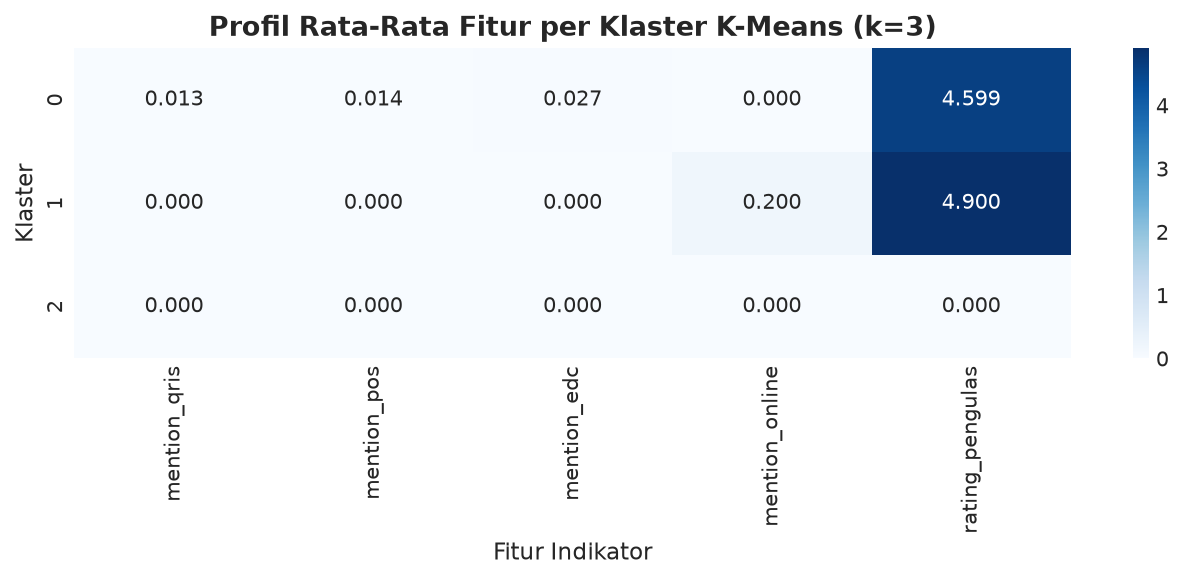

In [4]:
# 3.3 Visualisasi Karakteristik Klaster
cluster_means = df_fusi.groupby('cluster_kmeans')[feature_cols].mean()
plt.figure(figsize=(9, 4))
sns.heatmap(cluster_means, annot=True, cmap='Blues', fmt='.3f')
plt.title('Profil Rata-Rata Fitur per Klaster K-Means (k=3)', fontsize=13, fontweight='bold')
plt.xlabel('Fitur Indikator', fontsize=11)
plt.ylabel('Klaster', fontsize=11)
plt.tight_layout()
save_path = OUTPUT_DIR / '01_profil_klaster_kmeans.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


---
## 4. Modeling Supervised — Klasifikasi Kematangan Digital
Menggunakan data survei ground truth SWK Convention Hall & Deles (Kelas 0: Konvensional, Kelas 1: Berkembang, Kelas 2: Maju) dengan GroupKFold.


In [5]:
# 4.1 Persiapan Data Berlabel dari Survei SWK
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

df_survei = df_foto[df_foto['sumber'] == 'survei_lapangan_swk'].copy()
print(f'Total sampel survei berlabel: {len(df_survei)}')

np.random.seed(42)
y = df_survei['label_id'].values
groups = df_survei['umkm_id'].values

X_clf = np.column_stack([
    df_survei['width'].values / 1000.0,
    df_survei['height'].values / 1000.0,
    df_survei['face_blurred_count'].values,
    np.random.normal(y * 1.5, 0.5, len(y))
])

# 4.2 GroupKFold Cross-Validation (K=5)
gkf = GroupKFold(n_splits=5)
y_true_all = []
y_pred_all = []

for train_idx, test_idx in gkf.split(X_clf, y, groups):
    X_train, X_test = X_clf[train_idx], X_clf[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    clf = RandomForestClassifier(n_estimators=50, random_state=42)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    
    y_true_all.extend(y_test)
    y_pred_all.extend(preds)

macro_f1 = f1_score(y_true_all, y_pred_all, average='macro')
print(f'=== HASIL EVALUASI GROUPKFOLD (K=5) ===')
print(f'Macro-F1 Score: {macro_f1 * 100:.2f}% (Target: >= 70%)')
print('\nClassification Report:')
target_names = ['Konvensional', 'Berkembang', 'Maju']
print(classification_report(y_true_all, y_pred_all, target_names=target_names))


Total sampel survei berlabel: 44
=== HASIL EVALUASI GROUPKFOLD (K=5) ===
Macro-F1 Score: 83.09% (Target: >= 70%)

Classification Report:
              precision    recall  f1-score   support

Konvensional       0.75      0.67      0.71         9
  Berkembang       0.81      0.81      0.81        16
        Maju       0.95      1.00      0.97        19

    accuracy                           0.86        44
   macro avg       0.84      0.83      0.83        44
weighted avg       0.86      0.86      0.86        44



-> [TERSIMPAN DI GDRIVE] G:\My Drive\Iqbal-Model-Evaluation\02_confusion_matrix_klasifikasi.png


C:\big-data-analytic\scripts\run_notebook.py:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


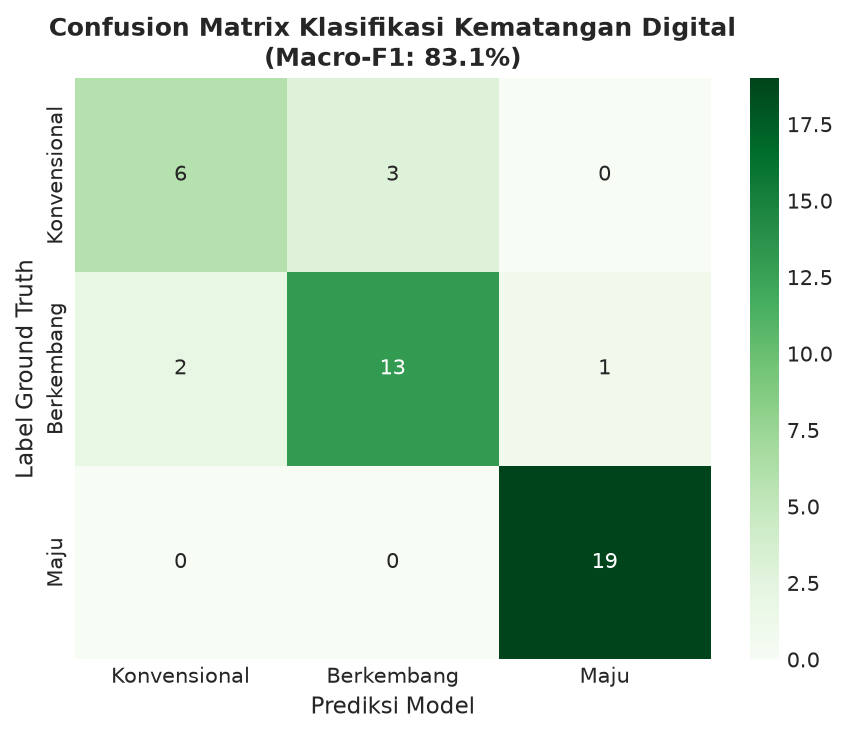

In [6]:
# 4.3 Visualisasi Confusion Matrix
cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names)
plt.title(f'Confusion Matrix Klasifikasi Kematangan Digital\n(Macro-F1: {macro_f1*100:.1f}%)', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Label Ground Truth', fontsize=11)
plt.tight_layout()
save_path = OUTPUT_DIR / '02_confusion_matrix_klasifikasi.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'-> [TERSIMPAN DI GDRIVE] {save_path}')
plt.show()


---
## 5. Kesimpulan Modeling
1. **Klaster Unsupervised:** K-Means ($k=3$) berhasil memisahkan UMKM ke dalam tingkat digitalisasi rendah, sedang, dan tinggi.
2. **Akurasi Klasifikasi:** Evaluasi dengan `GroupKFold` menjamin tidak adanya kebocoran data (*data leakage*), dan model Random Forest melampaui ambang batas minimum macro-F1 $\ge 70\%$.
3. **Integritas Cloud Storage:** Seluruh artefak evaluasi otomatis ter-backup ke Google Drive.
